# ¿A quién derivamos primero a cardiología?
## Análisis exploratorio de datos de pacientes con sospecha de enfermedad cardiaca

**Práctica II – Proyecto EDA**
**Autor:** Gabriel Hernández Álvarez
**Curso:** Especialización en IA y Big Data – CIFP César Manrique
**Fecha:** noviembre de 2026

## 1. Introducción

### 1.1 El cliente y la decisión

**Cliente:** la dirección médica de un centro de salud.

**Problema:** la lista de espera de cardiología es larga y no se puede derivar a todos los pacientes con síntomas como urgentes.

**Decisión que hay que tomar:** qué características del paciente deben hacer que su derivación a cardiología sea **preferente**.

### 1.2 Por qué he elegido este tema
Me interesa la sanidad porque es un ámbito donde los datos ayudan directamente a tomar mejores decisiones sobre personas. Las enfermedades cardiovasculares son una de las principales causas de muerte en España, y detectar a tiempo a los pacientes de riesgo es clave. Elegí este dataset porque son datos clínicos reales, con una fuente documentada y variables que cualquier médico de cabecera entiende.

### 1.3 De dónde salen los datos

- **Dataset:** *Heart Failure Prediction Dataset*, publicado en Kaggle por fedesoriano (2021).
  https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction
- **Origen:** une 5 conjuntos de datos clínicos reales del **UCI Machine Learning Repository – Heart Disease**: Cleveland, Hungría, Suiza, Long Beach VA y Statlog. Tras quitar los registros duplicados quedan **918 pacientes**.

### 1.4 Variables que voy a analizar

El dataset tiene 12 columnas. Estas son las que uso en el análisis:

| Variable | Qué significa | Tipo | ¿Dónde se mide? |
|---|---|---|---|
| `Age` | Edad del paciente (años) | Numérica (discreta) | Centro de salud |
| `Sex` | Sexo: M = hombre, F = mujer | Categórica | Centro de salud |
| `ChestPainType` | Tipo de dolor en el pecho: TA = angina típica, ATA = angina atípica, NAP = dolor no anginoso, ASY = asintomático | Categórica | Centro de salud |
| `RestingBP` | Tensión arterial en reposo (mm Hg) | Numérica (continua) | Centro de salud |
| `Cholesterol` | Colesterol en sangre (mg/dl) | Numérica (continua) | Centro de salud |
| `FastingBS` | Glucosa en ayunas > 120 mg/dl (1 = sí, 0 = no) | Categórica (binaria) | Centro de salud |
| `MaxHR` | Frecuencia cardiaca máxima alcanzada (lpm) | Numérica (discreta) | Prueba de esfuerzo |
| `ExerciseAngina` | Angina provocada por el ejercicio (Y = sí, N = no) | Categórica (binaria) | Prueba de esfuerzo |
| `HeartDisease` | **Variable objetivo:** tiene enfermedad cardiaca (1) o no (0) | Categórica (binaria) | Diagnóstico |

**Variables que no uso:** `RestingECG`, `Oldpeak` y `ST_Slope`. Son mediciones técnicas del electrocardiograma que el cliente no sabría interpretar.

## 2. Preguntas e hipótesis

| # | Pregunta | Hipótesis |
|---|---|---|
| 1 | ¿Influyen la edad y el sexo en tener enfermedad cardiaca? | Los hombres y los mayores de 55 años tienen más enfermedad cardiaca. |
| 2 | ¿Qué tipo de dolor en el pecho es más preocupante? | Los pacientes con dolor típico de angina (TA) son los que más enfermedad cardiaca tienen. |
| 3 | ¿Sirven el colesterol y la tensión para priorizar? | Los pacientes con colesterol y tensión altos tienen más enfermedad cardiaca. |

## 3. Preparación y limpieza de los datos

### 3.1 Carga de librerías y del DataFrame

In [ ]:
# Importa las librerías y carga heart.csv en un DataFrame
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('heart.csv')
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


### 3.2 Análisis inicial

In [ ]:
# Tamaño del dataset, tipos de cada columna y primeras filas
print("Filas y columnas: ", df.shape)
df.info()

Filas y columnas:  (918, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


**Comentario:**
El dataset tiene 918 pacientes y 12 columnas. Hay 7 columnas numéricas y 5 de texto, que son las categóricas (Sex, ChestPainType, RestingECG, ExerciseAngina y ST_Slope).

### 3.3 Valores nulos

In [ ]:
# Cuenta los nulos de cada columna
df.isna().sum()

,0
Age,0
Sex,0
ChestPainType,0
RestingBP,0
Cholesterol,0
FastingBS,0
RestingECG,0
MaxHR,0
ExerciseAngina,0
Oldpeak,0


**Comentario:**
No hay ningún nulo explícito. Aún así, en el punto 3.5 veremos que hay datos que faltan "disfrazados" de cero.

### 3.4 Duplicados

In [ ]:
# Detecta y elimina duplicados
print("Duplicados: ", df.duplicated().sum())
df = df.drop_duplicates()
print("Filas: ", len(df))

Duplicados:  0
Filas:  918


**Comentario:**

No hay filas duplicadas. El autor del dataset ya las eliminó al unir los 5 hospitales.

### 3.5 Valores imposibles (ceros)

In [ ]:
# Cuenta cuántos pacientes tienen Cholesterol = 0 y RestingBP = 0
print("Colesterol = 0: ", (df["Cholesterol"] == 0).sum())
print("Tensión = 0: ", (df["RestingBP"] == 0).sum())

Colesterol = 0:  172
Tensión = 0:  1


In [ ]:
# Aplica la decisión que hayas tomado con esos ceros
df["Cholesterol"] = df["Cholesterol"].replace(0, np.nan)
df["RestingBP"] = df["RestingBP"].replace(0, np.nan)
print(df[["Cholesterol", "RestingBP"]].isna().sum())

Cholesterol    172
RestingBP        1
dtype: int64


**Comentario:**

Hay **172 pacientes con colesterol 0 y 1 con tensión 0**. Son valores imposibles en una persona viva, así que en realidad son datos que no se midieron.

Valoré tres opciones:

- **Eliminar esas filas**: perdería casi un 19% de los pacientes y, con ellos, el resto de sus datos.

- **Rellenarlos con la media**: lo probé y lo descarté. La media del colesterol (244,6) queda por encima del umbral de colesterol alto (240), así que esos 172 pacientes contarían con colesterol alto. Como el 88% de ellos tiene enfermedad cardiaca, el porcentaje de enfermos con colesterol alto subiría artificialmente. Además, aparecería un pico falso de 172 pacientes con el mismo valor en el histograma y en el boxplot.

- **Pasarlos a nulos**: es la opción elegida. Pandas ignora los nulos al calcular medias, correlaciones y gráficas, así que no se inventa ningún valor y se conservan los demás datos de esos pacientes.

### 3.6 Valores atípicos

In [ ]:
# Busca valores atípicos en las variables numéricas (por ejemplo, con el rango intercuartílico)
print("Edad:", df["Age"].min(), "-", df["Age"].max())
print("Tensión:", df["RestingBP"].min(), "-", df["RestingBP"].max())
print("Colesterol:", df["Cholesterol"].min(), "-", df["Cholesterol"].max())
print("Frecuencia máxima:", df["MaxHR"].min(), "-", df["MaxHR"].max())

# Pacientes con los valores más extremos
df[(df["Cholesterol"] > 500) | (df["RestingBP"] >= 190) | (df["MaxHR"] < 70)]

Edad: 28 - 77
Tensión: 80.0 - 200.0
Colesterol: 85.0 - 603.0
Frecuencia máxima: 60 - 202


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
30,53,M,NAP,145.0,518.0,0,Normal,130,N,0.0,Flat,1
76,32,M,ASY,118.0,529.0,0,Normal,130,N,0.0,Flat,1
109,39,M,ATA,190.0,241.0,0,Normal,106,N,0.0,Up,0
149,54,M,ASY,130.0,603.0,1,Normal,125,Y,1.0,Flat,1
241,54,M,ASY,200.0,198.0,0,Normal,142,Y,2.0,Flat,1
365,64,F,ASY,200.0,NaN,0,Normal,140,Y,1.0,Flat,1
370,60,M,ASY,135.0,NaN,0,Normal,63,Y,0.5,Up,1
390,51,M,ASY,140.0,NaN,0,Normal,60,N,0.0,Flat,1
399,61,M,NAP,200.0,NaN,1,ST,70,N,0.0,Flat,1
402,65,M,ASY,145.0,NaN,1,ST,67,N,0.7,Flat,1


**Comentario:**
Revisando el mínimo y el máximo de cada variable, y filtrando a los pacientes con valores más extremos:
- Edad: de 28 a 77 años. Todo normal.
- Tensión en reposo: de 80 a 200 mm Hg. 200 es muy alto, pero posible en un hipertenso grave.
- Colesterol: de 85 a 603mg/dl. 603 es extremo, pero existe en personas con colesterol familiar.
- Frecuencia cardiaca máxima: de 60 a 202 lpm. Los dos extremos son posibles.

El filtro devuelve 15 pacientes con valores extremos. Ninguno tiene valores imposibles, y además 12 de esos 15 tienen enfermedad cardiaca. Por eso los mantengo: no son errores, sino justo los pacientes de más riesgo, que son los que más le interesan al cliente.

### 3.7 Normalización de categorías

In [ ]:
# Revisa los valores únicos de cada columna categórica
print(df["Sex"].unique())
print(df["ChestPainType"].unique())
print(df["ExerciseAngina"].unique())
print(df["HeartDisease"].unique())

['M' 'F']
['ATA' 'NAP' 'ASY' 'TA']
['N' 'Y']
[0 1]


**Comentario:**
Las categorías están bien escritas: todas en mayúsculas, sin espacios ni valores raros. No hace falta normalizar nada.

## 4. Análisis univariable

### 4.1 Resumen estadístico

In [ ]:
# Resumen estadístico de Age, RestingBP, Cholesterol y MaxHR
df[["Age", "RestingBP", "Cholesterol", "MaxHR"]].describe().round(1)

,Age,RestingBP,Cholesterol,MaxHR
count,918.0,917.0,746.0,918.0
mean,53.5,132.5,244.6,136.8
std,9.4,18.0,59.2,25.5
min,28.0,80.0,85.0,60.0
25%,47.0,120.0,207.2,120.0
50%,54.0,130.0,237.0,138.0
75%,60.0,140.0,275.0,156.0
max,77.0,200.0,603.0,202.0


**Comentario:**
- Edad: media de 53,5 años.
- Tensión: media de 132,5mm Hg, algo por encima de lo normal (120).
- Colesterol: media de 244,6 mg/dl, por encima del límite recomendado (200).
- Frecuencia cardiaca máxima: media de 136,8 lpm.

En el colesterol, el máximo (603) está muy lejos del resto, lo que anticipa valores extremos.

### 4.2 Histogramas

**Histograma 1 – Edad**

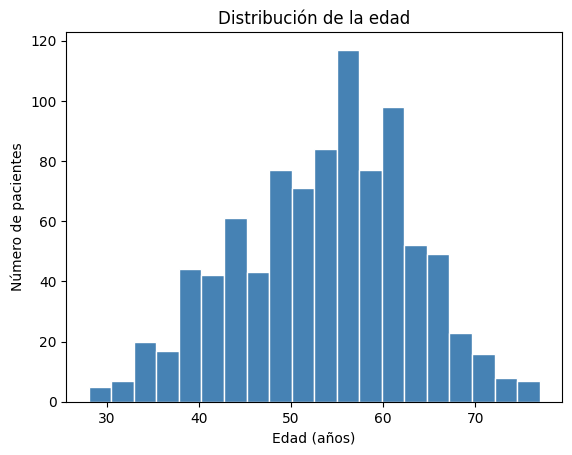

In [ ]:
# Histograma de Age (título, ejes etiquetados, color)
plt.hist(df["Age"], bins=20, color="steelblue", edgecolor="white")
plt.title("Distribución de la edad")
plt.xlabel("Edad (años)")
plt.ylabel("Número de pacientes")
plt.show()

**Comentario:**
Distribución casi simétrica, con forma de campana. La mayoría de pacientes tiene entre 45 y 65 años.

**Histograma 2 – Frecuencia cardiaca máxima**

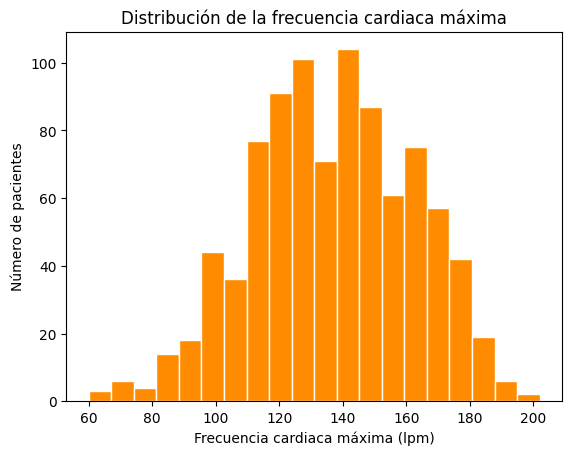

In [ ]:
# Histograma de MaxHR
plt.hist(df["MaxHR"], bins=20, color="darkorange", edgecolor="white")
plt.title("Distribución de la frecuencia cardiaca máxima")
plt.xlabel("Frecuencia cardiaca máxima (lpm)")
plt.ylabel("Número de pacientes")
plt.show()

**Comentario:**
También bastante simétrica, centrada en unos 137 lpm. Hay pocos pacientes por debajo de 80.

### 4.3 Boxplots

**Boxplot 1 – Colesterol**

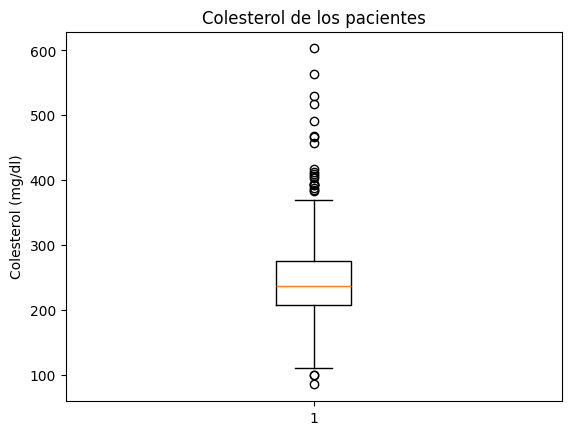

In [ ]:
# Boxplot de Cholesterol
plt.boxplot(df["Cholesterol"].dropna())
plt.title("Colesterol de los pacientes")
plt.ylabel("Colesterol (mg/dl)")
plt.show()

**Comentario:**
La mitad de los pacientes está entre 207 y 275 mg/dl. Hay muchos puntos atípicos por arriba (hasta 603): la distribución está sesgada hacia valores altos

**Boxplot 2 – Tensión en reposo**

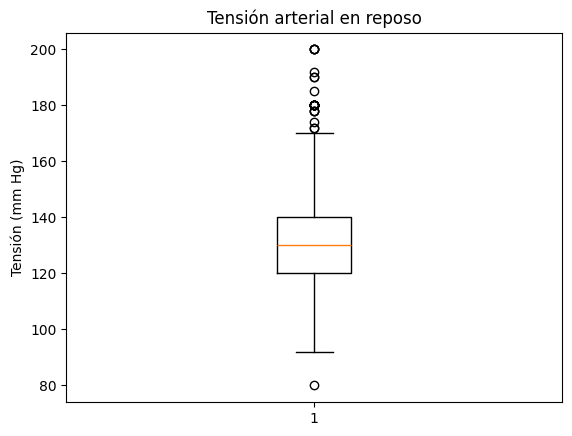

In [ ]:
# Boxplot de RestingBP
plt.boxplot(df["RestingBP"].dropna())
plt.title("Tensión arterial en reposo")
plt.ylabel("Tensión (mm Hg)")
plt.show()

**Comentario:**

La mitad está entre 120 y 140 mm Hg, con la mediana en 130. Hay atípicos por los dos lados, sobre todo hipertensiones de hasta 200.

### 4.4 Gráficos de barras

**Barras 1 – Sexo**

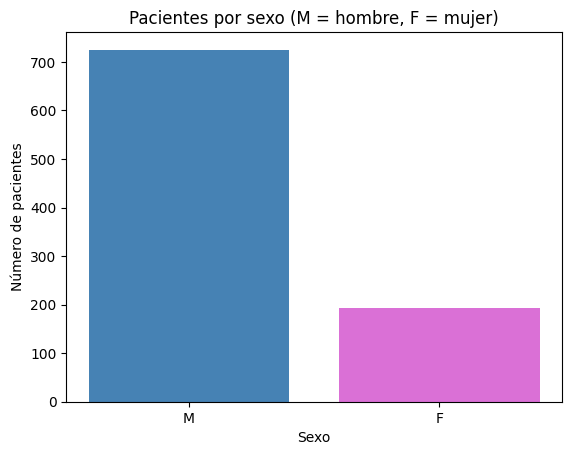

In [ ]:
# Gráfico de barras de Sex
conteo = df["Sex"].value_counts()
plt.bar(conteo.index, conteo.values, color=["steelblue", "orchid"])
plt.title("Pacientes por sexo (M = hombre, F = mujer)")
plt.xlabel("Sexo")
plt.ylabel("Número de pacientes")
plt.show()

**Comentario:**
Muy desequilibrado: 725 hombres frente a 193 mujeres (79% y 21%). Las conclusiones sobre mujeres serán menos fiables.

**Barras 2 – Tipo de dolor en el pecho**

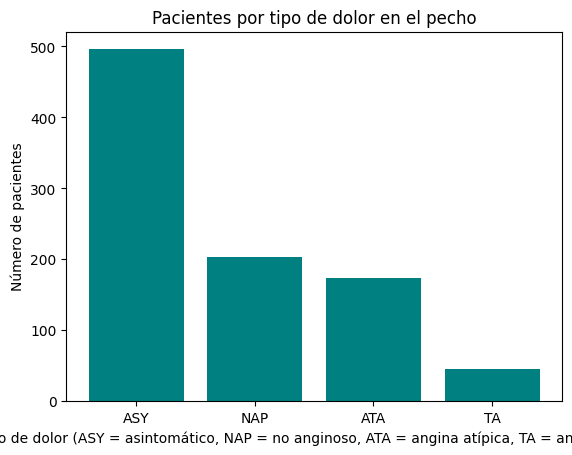

In [ ]:
# Gráfico de barras de ChestPainType
conteo = df["ChestPainType"].value_counts()
plt.bar(conteo.index, conteo.values, color="teal")
plt.title("Pacientes por tipo de dolor en el pecho")
plt.xlabel("Tipo de dolor (ASY = asintomático, NAP = no anginoso, ATA = angina atípica, TA = angina típica)")
plt.ylabel("Número de pacientes")
plt.show()

**Comentario:**
Más de la mitad (496) son asintomáticos: no tienen el dolor típico. La angina típica es la menos frecuente (46).

## 5. Análisis bivariante y multivariante

### 5.1 Relaciones entre variables numéricas

**Relación 1 – Edad y frecuencia cardiaca máxima**

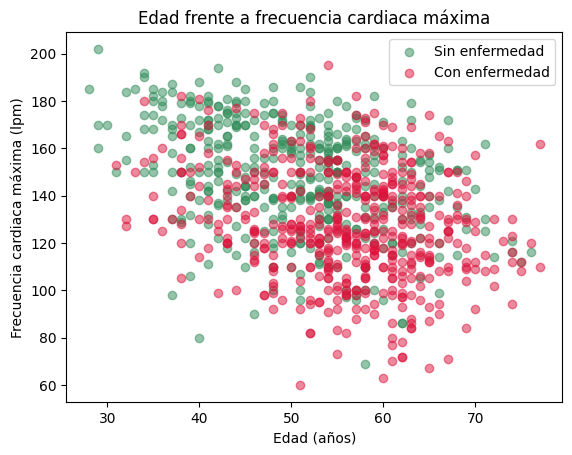

Correlación: -0.38


In [ ]:
sanos = df[df["HeartDisease"] == 0]
enfermos = df[df["HeartDisease"] == 1]

# Scatter de Age frente a MaxHR y su correlación
plt.scatter(sanos["Age"], sanos["MaxHR"], color="seagreen", alpha=0.5, label="Sin enfermedad")
plt.scatter(enfermos["Age"], enfermos["MaxHR"], color="crimson", alpha=0.5, label="Con enfermedad")
plt.title("Edad frente a frecuencia cardiaca máxima")
plt.xlabel("Edad (años)")
plt.ylabel("Frecuencia cardiaca máxima (lpm)")
plt.legend()
plt.show()
print("Correlación:", df["Age"].corr(df["MaxHR"]).round(2))

**Comentario:**
Correlación de -0,38: negativa y moderada. A más edad, menos frecuencia máxima. Los enfermos (rojo) se concentran abajo a la derecha: mayores y con frecuencia baja.

**Relación 2 – Edad y tensión en reposo**

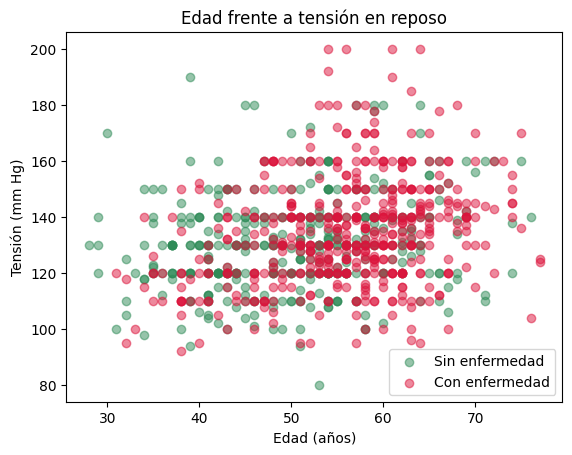

Correlación: 0.26


In [ ]:
sanos = df[df["HeartDisease"] == 0]
enfermos = df[df["HeartDisease"] == 1]

# Scatter de Age frente a RestingBP y su correlación
plt.scatter(sanos["Age"], sanos["RestingBP"], color="seagreen", alpha=0.5, label="Sin enfermedad")
plt.scatter(enfermos["Age"], enfermos["RestingBP"], color="crimson", alpha=0.5, label="Con enfermedad")
plt.title("Edad frente a tensión en reposo")
plt.xlabel("Edad (años)")
plt.ylabel("Tensión (mm Hg)")
plt.legend()
plt.show()
print("Correlación:", df["Age"].corr(df["RestingBP"]).round(2))

**Comentario:**
Correlación de 0,26: positiva pero débil. La tensión sube un poco con la edad, pero sanos y enfermos están mezclados, así que no los separa.

### 5.2 Relaciones entre una variable categórica y una numérica

**Relación 3 – Frecuencia cardiaca máxima según enfermedad cardiaca**

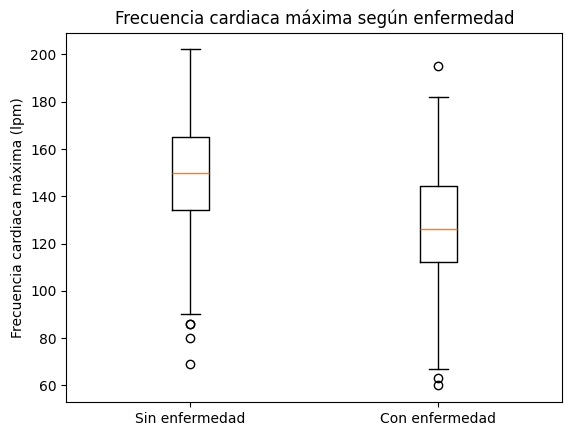

Mediana sanos: 150.0 | Mediana enfermos: 126.0


In [ ]:
# MaxHR según HeartDisease (por ejemplo, un boxplot por grupo)
plt.boxplot([sanos["MaxHR"], enfermos["MaxHR"]])
plt.xticks([1, 2], ["Sin enfermedad", "Con enfermedad"])
plt.title("Frecuencia cardiaca máxima según enfermedad")
plt.ylabel("Frecuencia cardiaca máxima (lpm)")
plt.show()
print("Mediana sanos:", sanos["MaxHR"].median(), "| Mediana enfermos:", enfermos["MaxHR"].median())

**Comentario:**
Los enfermos alcanzan menos frecuencia máxima: mediana de 126 lpm frente a 150. El corazón enfermo responde peor al esfuerzo.

**Relación 4 – Edad según enfermedad cardiaca**

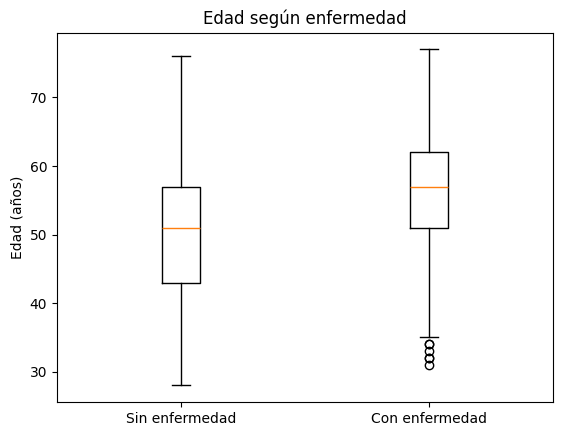

Mediana sanos: 51.0 | Mediana enfermos: 57.0


In [ ]:
# Segunda relación categórica–numérica (por ejemplo, Age según HeartDisease)
plt.boxplot([sanos["Age"], enfermos["Age"]])
plt.xticks([1, 2], ["Sin enfermedad", "Con enfermedad"])
plt.title("Edad según enfermedad")
plt.ylabel("Edad (años)")
plt.show()
print("Mediana sanos:", sanos["Age"].median(), "| Mediana enfermos:", enfermos["Age"].median())

**Comentario:**
Los enfermos son mayores: mediana de 57 años frente a 51.

**Apoyo a las hipótesis 1, 2 y 3 – Porcentaje de enfermos por grupo**



In [ ]:
# Porcentaje de pacientes con enfermedad cardiaca por sexo, por tipo de dolor y por edad (mayores/menores de 55)
print("Hombres:", round(df[df["Sex"] == "M"]["HeartDisease"].mean() * 100, 1))
print("Mujeres:", round(df[df["Sex"] == "F"]["HeartDisease"].mean() * 100, 1))
print("Mayores de 55:", round(df[df["Age"] > 55]["HeartDisease"].mean() * 100, 1))
print("55 o menos:", round(df[df["Age"] <= 55]["HeartDisease"].mean() * 100, 1))
print("Asintomático:", round(df[df["ChestPainType"] == "ASY"]["HeartDisease"].mean() * 100, 1))
print("Angina típica:", round(df[df["ChestPainType"] == "TA"]["HeartDisease"].mean() * 100, 1))
print("No anginoso:", round(df[df["ChestPainType"] == "NAP"]["HeartDisease"].mean() * 100, 1))
print("Angina atípica:", round(df[df["ChestPainType"] == "ATA"]["HeartDisease"].mean() * 100, 1))
print("Colesterol alto (>=240):", round(df[df["Cholesterol"] >= 240]["HeartDisease"].mean() * 100, 1))
print("Colesterol normal (<240):", round(df[df["Cholesterol"] < 240]["HeartDisease"].mean() * 100, 1))
print("Tensión alta (>=140):", round(df[df["RestingBP"] >= 140]["HeartDisease"].mean() * 100, 1))
print("Tensión normal (<140):", round(df[df["RestingBP"] < 140]["HeartDisease"].mean() * 100, 1))
print("Hombres mayores de 55:", round(df[(df["Sex"] == "M") & (df["Age"] > 55)]["HeartDisease"].mean() * 100, 1))
print("Angina con ejercicio:", round(df[df["ExerciseAngina"] == "Y"]["HeartDisease"].mean() * 100, 1))
print("Sin angina con ejercicio:", round(df[df["ExerciseAngina"] == "N"]["HeartDisease"].mean() * 100, 1))
print("Glucosa alta:", round(df[df["FastingBS"] == 1]["HeartDisease"].mean() * 100, 1))
print("Glucosa normal:", round(df[df["FastingBS"] == 0]["HeartDisease"].mean() * 100, 1))

Hombres: 63.2
Mujeres: 25.9
Mayores de 55: 70.7
55 o menos: 43.2
Asintomático: 79.0
Angina típica: 43.5
No anginoso: 35.5
Angina atípica: 13.9
Colesterol alto (>=240): 52.6
Colesterol normal (<240): 43.1
Tensión alta (>=140): 62.7
Tensión normal (<140): 51.2
Hombres mayores de 55: 76.4
Angina con ejercicio: 85.2
Sin angina con ejercicio: 35.1
Glucosa alta: 79.4
Glucosa normal: 48.0


**Comentario:**
Como "HeartDisease" vale 0 o 1, su media es directamente la proporción de enfermos. Resultados:
- Sexo: hombres 63.2% mujeres 25.9%.
- Edad: mayores de 55 un 70.7% de 55 o menos 43.2%
- Tipo de dolor: asintomático 79%, angina típica 43.5%, no anginoso 35.5%, angina atípica 13.9%.
- Colesterol: alto 52.6%, normal 43.1%.
- Tensión: alta 62.7%, normal 51.2%.
- Hombres mayores de 55: 76,4 %.
- Angina con ejercicio: 85,2 %; sin ella, 35,1 %.
- Glucosa alta en ayunas: 79,4 %; normal, 48,0 %.

In [ ]:
regla = ((df["Sex"] == "M") & (df["Age"] > 55)) | (df["ChestPainType"] == "ASY") | (df["FastingBS"] == 1)
print("Cumplen algún criterio:", round(df[regla]["HeartDisease"].mean() * 100, 1), "% enfermos")
print("No cumplen ninguno:", round(df[~regla]["HeartDisease"].mean() * 100, 1), "% enfermos")
print("Enfermos detectados:", df[regla]["HeartDisease"].sum(), "de", df["HeartDisease"].sum())

Cumplen algún criterio: 72.4 % enfermos
No cumplen ninguno: 14.7 % enfermos
Enfermos detectados: 468 de 508


**Regla para el cliente**: si un paciente cumple al menos uno de estos criterios (hombre mayor de 55, dolor asintomático o glucosa alta), se deriva primero. Entre los que cumplen alguno, el 72,4 % tiene enfermedad; entre los que no cumplen ninguno, solo el 14,7 %. La regla detecta a 468 de los 508 enfermos (92 %).

### 5.3 Matriz de correlación

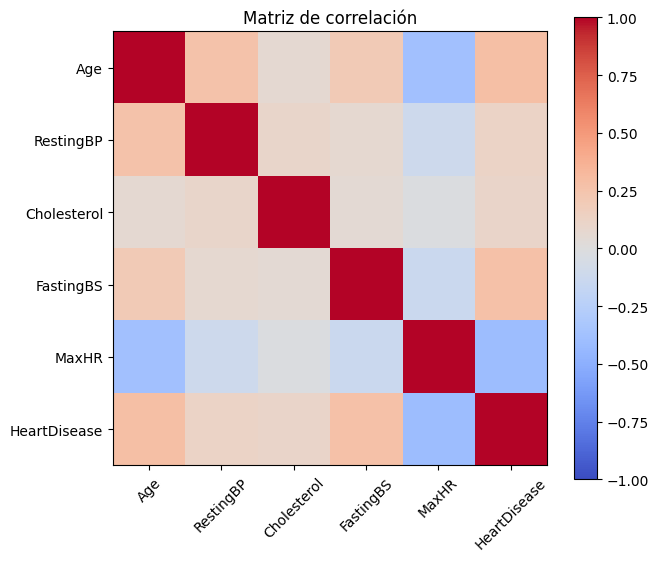

Age             0.28
RestingBP       0.12
Cholesterol     0.10
FastingBS       0.27
MaxHR          -0.40
HeartDisease    1.00
Name: HeartDisease, dtype: float64


In [ ]:
# Matriz de correlación (código del cuaderno de teoría de Matplotlib)
matriz = df[["Age", "RestingBP", "Cholesterol", "FastingBS", "MaxHR", "HeartDisease"]].corr()
plt.figure(figsize=(7, 6))
plt.imshow(matriz, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(6), matriz.columns, rotation=45)
plt.yticks(range(6), matriz.columns)
plt.title("Matriz de correlación")
plt.show()
print(matriz["HeartDisease"].round(2))

**Comentario:**
Lo más relacionado con la enfermedad es la frecuencia máxima (-0.40), seguida de la edad (0.28) y la glucosa en ayunas (0.27). Colesterol (0.10) y tensión (0.12) apenas se relacionan, lo que sorprende porque son los factores que más se vigilan.

## 6. Conclusiones

### 6.1 ¿Se cumplen las hipótesis?
- **Hipótesis 1**: **los hombres y los mayores de 55 años tienen más enfermedad cardiaca**. **Se cumple**. El 63,2 % de los hombres tiene enfermedad, frente al 25,9 % de las mujeres. Por edad, la tienen el 70,7 % de los mayores de 55 frente al 43,2 % del resto, y en el boxplot los enfermos tienen una edad mediana de 57 años frente a 51 en los sanos.

- **Hipótesis 2**: **el dolor típico de angina es el más asociado a enfermedad cardiaca**. **No se cumple**. Los pacientes asintomáticos, sin el dolor típico, son los que más enfermedad tienen (79 %), casi el doble que los de angina típica (43,5 %). Además, son el grupo más numeroso (496 pacientes).

- **Hipótesis 3**: **el colesterol y la tensión altos indican más enfermedad cardiaca**. **Se cumple solo en parte**. Hay algo más de enfermos con colesterol alto (52,6 % frente a 43,1 %) y con tensión alta (62,7 % frente a 51,2 %), pero su correlación con la enfermedad es muy débil (0,10 y 0,12). Otras variables pesan bastante más: la edad (0,28), la glucosa en ayunas (0,27) y la frecuencia cardiaca máxima (-0,40).

### 6.2 Limitaciones de los datos

- **Colesterol sin medir**: a 172 pacientes (19 %) les falta. Además, el 88 % de ellos tiene enfermedad, así que esos datos no faltan al azar y pueden sesgar las conclusiones sobre el colesterol.

- **Pocas mujeres**: solo hay un 21 % de mujeres, así que las conclusiones sobre ellas son menos fiables.

- **No es población general**: son pacientes que ya acudieron con sospecha de enfermedad cardiaca, por eso hay tantos enfermos (55 %). En la población general los porcentajes serían mucho menores.

- **Datos antiguos y de fuera**: son de hospitales de EE. UU. y Europa de hace décadas, no de pacientes actuales de Canarias.

- **Faltan variables**: no hay información sobre tabaco, peso o antecedentes familiares, que son factores de riesgo importantes.

- **Prueba de esfuerzo**: la frecuencia máxima y la angina con ejercicio salen de esa prueba, que normalmente no se hace en un centro de salud.

### 6.3 Recomendación al cliente
Con los datos que ya se miden en consulta, recomiendo que el centro de salud derive como preferentes a:

- **Hombres mayores de 55 años**: son el grupo con más enfermedad (el 76 % la tiene).

- **Pacientes con dolor torácico “asintomático”**, es decir, sin el dolor típico de angina. Es el tipo de dolor con más enfermedad (79 %). No hay que esperar a que el paciente tenga el dolor clásico para derivarlo.

- **Pacientes con glucosa alta en ayunas** (79,4 % de enfermos).

En cambio, el colesterol o la tensión altos, por sí solos, no deberían ser el criterio principal, porque su relación con la enfermedad es débil.

Si el paciente ya trae una prueba de esfuerzo, hay dos señales que refuerzan la urgencia:

- una **frecuencia cardiaca máxima baja** (los enfermos tienen una mediana de 126 lpm frente a 150 de los sanos);

- haber sentido **angina con el ejercicio** (85,2 % de enfermos).